In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("GPU available:", torch.cuda.is_available())

transform = transforms.Compose([transforms.ToTensor()])
trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Flatten images to 784-dim vectors for simplicity (NOC operates on input-space distance)
train_images = trainset.data.numpy().reshape(-1, 784).astype(np.float32) / 255.0
train_labels = trainset.targets.numpy()
test_images = testset.data.numpy().reshape(-1, 784).astype(np.float32) / 255.0
test_labels = testset.targets.numpy()

print(f"Train: {train_images.shape}, Test: {test_images.shape}")

GPU available: True


100%|██████████| 9.91M/9.91M [00:00<00:00, 44.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.02MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.68MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.62MB/s]


Train: (60000, 784), Test: (10000, 784)


In [2]:
class NOCAgent:
    def __init__(self, prototype, label):
        self.prototype = prototype.copy()
        self.label = label
        self.correct_count = 1
        self.total_count = 1

    @property
    def fitness(self):
        return self.correct_count / self.total_count

def train_noc(train_images, train_labels, novelty_threshold=8.0, learning_rate=0.05, max_agents=500, prune_every=2000):
    agents = []

    for step, (x, y) in enumerate(zip(train_images, train_labels)):
        if len(agents) == 0:
            agents.append(NOCAgent(x, y))
            continue

        # Find nearest agent
        distances = [np.linalg.norm(x - a.prototype) for a in agents]
        nearest_idx = np.argmin(distances)
        nearest_dist = distances[nearest_idx]

        if nearest_dist > novelty_threshold:
            # Novel input: spawn new agent
            if len(agents) < max_agents:
                agents.append(NOCAgent(x, y))
        else:
            # Match found: update agent
            agent = agents[nearest_idx]
            agent.total_count += 1
            if agent.label == y:
                agent.correct_count += 1
                agent.prototype += learning_rate * (x - agent.prototype)
            else:
                # Wrong prediction: agent might be in the wrong niche, weaken it
                pass

        # Periodic pruning of weak agents
        if (step + 1) % prune_every == 0 and len(agents) > 20:
            agents = [a for a in agents if a.fitness > 0.3 or a.total_count < 10]

        if (step + 1) % 10000 == 0:
            print(f"Step {step+1}/{len(train_images)}, Agents: {len(agents)}")

    return agents

print("NOC functions ready")

NOC functions ready


In [3]:
import time

subset_size = 5000
start = time.time()
agents = train_noc(train_images[:subset_size], train_labels[:subset_size], novelty_threshold=8.0, learning_rate=0.05, max_agents=300)
elapsed = time.time() - start

print(f"\nTraining complete: {len(agents)} agents formed")
print(f"Time: {elapsed:.1f} sec for {subset_size} samples")


Training complete: 191 agents formed
Time: 3.0 sec for 5000 samples


In [4]:
start = time.time()
agents_full = train_noc(train_images, train_labels, novelty_threshold=8.0, learning_rate=0.05, max_agents=500)
elapsed = time.time() - start

print(f"\nTraining complete: {len(agents_full)} agents formed")
print(f"Time: {elapsed/60:.1f} min for {len(train_images)} samples")

Step 10000/60000, Agents: 236
Step 20000/60000, Agents: 285
Step 30000/60000, Agents: 306
Step 40000/60000, Agents: 319
Step 50000/60000, Agents: 343
Step 60000/60000, Agents: 361

Training complete: 361 agents formed
Time: 1.2 min for 60000 samples


In [5]:
def predict_noc(agents, x):
    distances = [np.linalg.norm(x - a.prototype) for a in agents]
    nearest_idx = np.argmin(distances)
    return agents[nearest_idx].label

predictions = [predict_noc(agents_full, x) for x in test_images]
accuracy = np.mean(np.array(predictions) == test_labels)
print(f"NOC test accuracy: {accuracy*100:.2f}%")

# Per-digit breakdown
from collections import defaultdict
correct_per_digit = defaultdict(int)
total_per_digit = defaultdict(int)
for pred, true in zip(predictions, test_labels):
    total_per_digit[true] += 1
    if pred == true:
        correct_per_digit[true] += 1

print("\nPer-digit accuracy:")
for digit in range(10):
    acc = 100 * correct_per_digit[digit] / total_per_digit[digit]
    print(f"Digit {digit}: {acc:.1f}%")

NOC test accuracy: 90.74%

Per-digit accuracy:
Digit 0: 95.7%
Digit 1: 98.6%
Digit 2: 92.9%
Digit 3: 87.6%
Digit 4: 88.6%
Digit 5: 90.9%
Digit 6: 95.2%
Digit 7: 89.3%
Digit 8: 88.4%
Digit 9: 79.4%


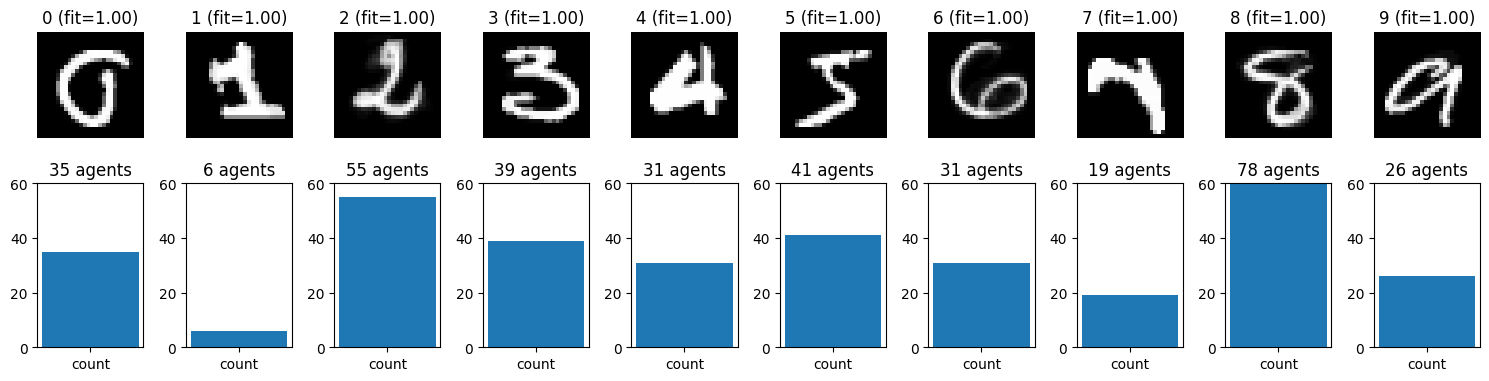


Agents per digit:
Digit 0: 35 agents
Digit 1: 6 agents
Digit 2: 55 agents
Digit 3: 39 agents
Digit 4: 31 agents
Digit 5: 41 agents
Digit 6: 31 agents
Digit 7: 19 agents
Digit 8: 78 agents
Digit 9: 26 agents


In [6]:
fig, axes = plt.subplots(2, 10, figsize=(15, 4))
for digit in range(10):
    digit_agents = [a for a in agents_full if a.label == digit]
    if len(digit_agents) > 0:
        best_agent = max(digit_agents, key=lambda a: a.fitness)
        axes[0, digit].imshow(best_agent.prototype.reshape(28, 28), cmap='gray')
        axes[0, digit].set_title(f"{digit} (fit={best_agent.fitness:.2f})")
        axes[0, digit].axis('off')

        axes[1, digit].bar(['count'], [len(digit_agents)])
        axes[1, digit].set_title(f"{len(digit_agents)} agents")
        axes[1, digit].set_ylim(0, 60)

plt.tight_layout()
plt.show()

print("\nAgents per digit:")
for digit in range(10):
    count = sum(1 for a in agents_full if a.label == digit)
    print(f"Digit {digit}: {count} agents")